In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, recall_score,
                             precision_score, f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.frameon': False})
NAT, MAN, NEU, PUR, GRY = 'blue', 'red', 'green', 'purple', 'gray'
SEED = 42
FIG = 'figures_method'
os.makedirs(FIG, exist_ok=True)

def save(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [2]:

candidates = []
try:
    from google.colab import drive
    drive.mount('/content/drive')
    candidates.append('/content/drive/MyDrive/DATA 490-Capstone Project')
except Exception:
    pass
candidates += ['/content', '.', 'data']

path = None
for d in candidates:
    p = os.path.join(d, 'seismic_model_table.csv')
    if os.path.exists(p):
        path = p
        break
if path is None:
    raise FileNotFoundError('Put seismic_model_table.csv in the Drive folder DATA 490-Capstone Project.')

df = pd.read_csv(path)
print('Using:', path)
print('Rows:', df.shape[0], ' Columns:', df.shape[1], ' Missing values:', int(df.isnull().sum().sum()))
print(df.dtypes)
print('\nEvents per year and human caused share')
print(df.groupby('year')['is_manmade'].agg(events='size', human_caused='sum', share='mean').round(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using: /content/drive/MyDrive/DATA 490-Capstone Project/seismic_model_table.csv
Rows: 33181  Columns: 8  Missing values: 0
latitude      float64
longitude     float64
mag           float64
year            int64
month           int64
hour            int64
depth         float64
is_manmade      int64
dtype: object

Events per year and human caused share
      events  human_caused  share
year                             
2000    6240           657  0.105
2001    6140           831  0.135
2002    4871           572  0.117
2003    5324           214  0.040
2004    6189           237  0.038
2005    4417           230  0.052


In [3]:

nat = df[df['is_manmade'] == 0]
man = df[df['is_manmade'] == 1]
rows = []
for col in ['depth', 'hour', 'mag', 'longitude', 'latitude']:
    u = stats.mannwhitneyu(man[col], nat[col])
    ks = stats.ks_2samp(man[col], nat[col])
    rows.append([col, nat[col].median(), man[col].median(), u.pvalue, ks.statistic])
tests = pd.DataFrame(rows, columns=['variable', 'median_earthquake', 'median_human_caused', 'mann_whitney_p', 'ks_distance']).round(4)
print(tests)

east = (df['longitude'] > -114).astype(int)
ct = pd.crosstab(east, df['is_manmade'])
chi = stats.chi2_contingency(ct)
print('\nChi square test, east or west of -114 against event type')
print(ct)
print('chi square', round(chi[0], 1), ' p value', chi[1])

r_all = stats.spearmanr(df['mag'], df['depth'])
r_nat = stats.spearmanr(nat['mag'], nat['depth'])
print('\nSpearman magnitude and depth: all', round(r_all.statistic, 3), 'p', round(r_all.pvalue, 3),
      '| earthquakes', round(r_nat.statistic, 3), 'p', r_nat.pvalue)

    variable  median_earthquake  median_human_caused  mann_whitney_p  \
0      depth             5.6175                0.000             0.0   
1       hour            12.0000               20.000             0.0   
2        mag             2.3000                2.600             0.0   
3  longitude          -118.7213             -109.157             0.0   
4   latitude            36.0328               40.277             0.0   

   ks_distance  
0       0.9124  
1       0.5801  
2       0.2924  
3       0.6834  
4       0.4088  

Chi square test, east or west of -114 against event type
is_manmade      0     1
longitude              
0           28562   810
1            1878  1931
chi square 10218.1  p value 0.0

Spearman magnitude and depth: all -0.004 p 0.446 | earthquakes 0.056 p 1.0199088887645853e-22


In [4]:

YEARS = sorted(df['year'].unique())
FEAT_DEPTH = ['latitude', 'longitude', 'mag', 'year', 'month', 'hour']
FEAT_DEPTH_PLUS = FEAT_DEPTH + ['is_manmade']
FEAT_TYPE = ['latitude', 'longitude', 'mag', 'month', 'hour']
inner_cv = GroupKFold(n_splits=3)

def tune(model, grid, X, y, groups, scoring):
    if not grid:
        return clone(model).fit(X, y), {}
    gs = GridSearchCV(model, grid, cv=inner_cv, scoring=scoring, n_jobs=-1)
    gs.fit(X, y, groups=groups)
    return gs.best_estimator_, gs.best_params_

In [5]:

depth_models = {
    'Baseline mean':    (DummyRegressor(strategy='mean'), {}),
    'Baseline median':  (DummyRegressor(strategy='median'), {}),
    'Linear Regression': (make_pipeline(StandardScaler(), LinearRegression()), {}),
    'KNN': (make_pipeline(StandardScaler(), KNeighborsRegressor()),
            {'kneighborsregressor__n_neighbors': [5, 15, 30]}),
    'Random Forest': (RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED),
                      {'min_samples_leaf': [5, 20]}),
    'XGBoost': (XGBRegressor(n_estimators=150, learning_rate=0.05, n_jobs=2, random_state=SEED),
                {'max_depth': [3, 5]}),
}

fitted = {}

def run_depth(features, tag):
    res, preds, chosen = [], {}, []
    for yr in YEARS:
        tr, te = df[df['year'] != yr], df[df['year'] == yr]
        Xtr, ytr, Xte, yte = tr[features], tr['depth'], te[features], te['depth']
        for name, (model, grid) in depth_models.items():
            best, par = tune(model, grid, Xtr, ytr, tr['year'], 'neg_mean_absolute_error')
            fitted[(tag, name, yr)] = best
            p = best.predict(Xte)
            res.append([name, yr, mean_absolute_error(yte, p), np.sqrt(mean_squared_error(yte, p)), r2_score(yte, p)])
            preds.setdefault(name, []).append(pd.Series(p, index=te.index))
            chosen.append([name, yr, str(par)])
    out = pd.DataFrame(res, columns=['model', 'held_out_year', 'MAE', 'RMSE', 'R2'])
    preds = {k: pd.concat(v).sort_index() for k, v in preds.items()}
    return out, preds, pd.DataFrame(chosen, columns=['model', 'held_out_year', 'best_settings'])

depth_A, preds_A, chosen_A = run_depth(FEAT_DEPTH, 'A')
depth_B, preds_B, chosen_B = run_depth(FEAT_DEPTH_PLUS, 'B')

def summarize(res):
    s = res.groupby('model')[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(3)
    return s.sort_values(('MAE', 'mean'))
print('Depth, six predictors. Mean and standard deviation over the six held out years')
print(summarize(depth_A))
print('\nDepth, six predictors plus is_manmade')
print(summarize(depth_B))

Depth, six predictors. Mean and standard deviation over the six held out years
                     MAE          RMSE            R2       
                    mean    std   mean    std   mean    std
model                                                      
Random Forest      2.325  0.168  4.028  0.355  0.522  0.056
XGBoost            2.622  0.122  4.248  0.308  0.468  0.049
KNN                3.525  0.302  5.322  0.395  0.164  0.086
Baseline median    3.913  0.253  5.924  0.228 -0.034  0.028
Linear Regression  3.927  0.127  5.665  0.288  0.054  0.057
Baseline mean      3.980  0.270  5.850  0.210 -0.009  0.007

Depth, six predictors plus is_manmade
                     MAE          RMSE            R2       
                    mean    std   mean    std   mean    std
model                                                      
Random Forest      2.283  0.193  4.003  0.373  0.528  0.059
XGBoost            2.517  0.161  4.201  0.290  0.480  0.049
KNN                3.390  0.312  5.213  0.

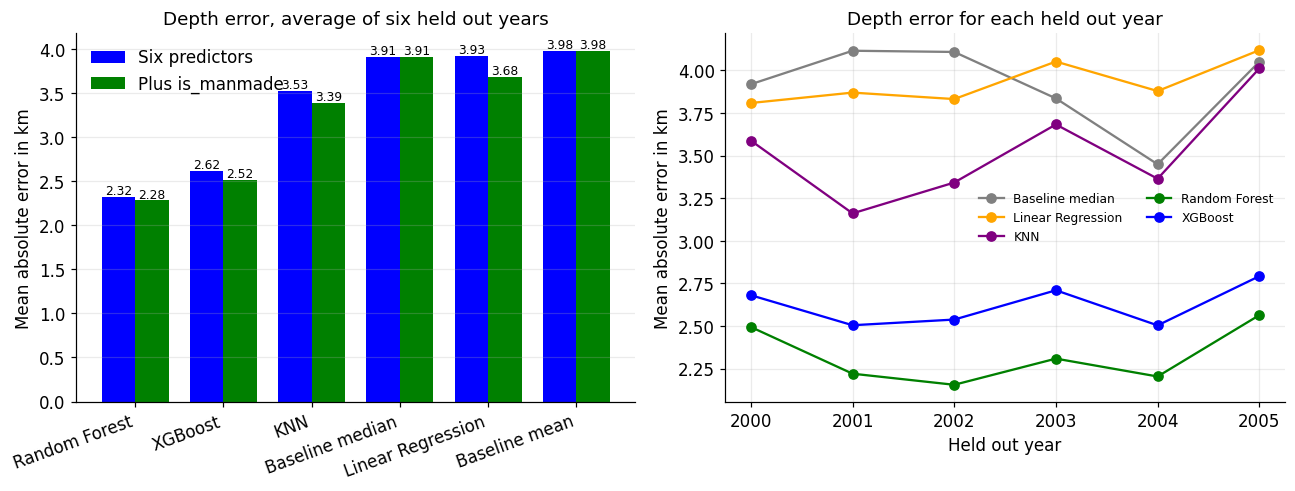

In [6]:

order = summarize(depth_A).index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
w = 0.38
x = np.arange(len(order))
mA = depth_A.groupby('model')['MAE'].mean().reindex(order)
mB = depth_B.groupby('model')['MAE'].mean().reindex(order)
ax[0].bar(x - w / 2, mA.values, w, color=NAT, label='Six predictors')
ax[0].bar(x + w / 2, mB.values, w, color=NEU, label='Plus is_manmade')
for i, (a, b) in enumerate(zip(mA.values, mB.values)):
    ax[0].text(i - w / 2, a + 0.03, f'{a:.2f}', ha='center', fontsize=8)
    ax[0].text(i + w / 2, b + 0.03, f'{b:.2f}', ha='center', fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=20, ha='right')
ax[0].set_ylabel('Mean absolute error in km'); ax[0].set_title('Depth error, average of six held out years')
ax[0].legend(); ax[0].grid(axis='x', alpha=0)
piv = depth_A.pivot(index='held_out_year', columns='model', values='MAE')[['Baseline median', 'Linear Regression', 'KNN', 'Random Forest', 'XGBoost']]
cols = [GRY, 'orange', PUR, NEU, NAT]
for c, col in zip(piv.columns, cols):
    ax[1].plot(piv.index, piv[c], marker='o', color=col, label=c)
ax[1].set_xlabel('Held out year'); ax[1].set_ylabel('Mean absolute error in km')
ax[1].set_title('Depth error for each held out year'); ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); save('fig01_depth_models')

Best depth model (six predictors): Random Forest


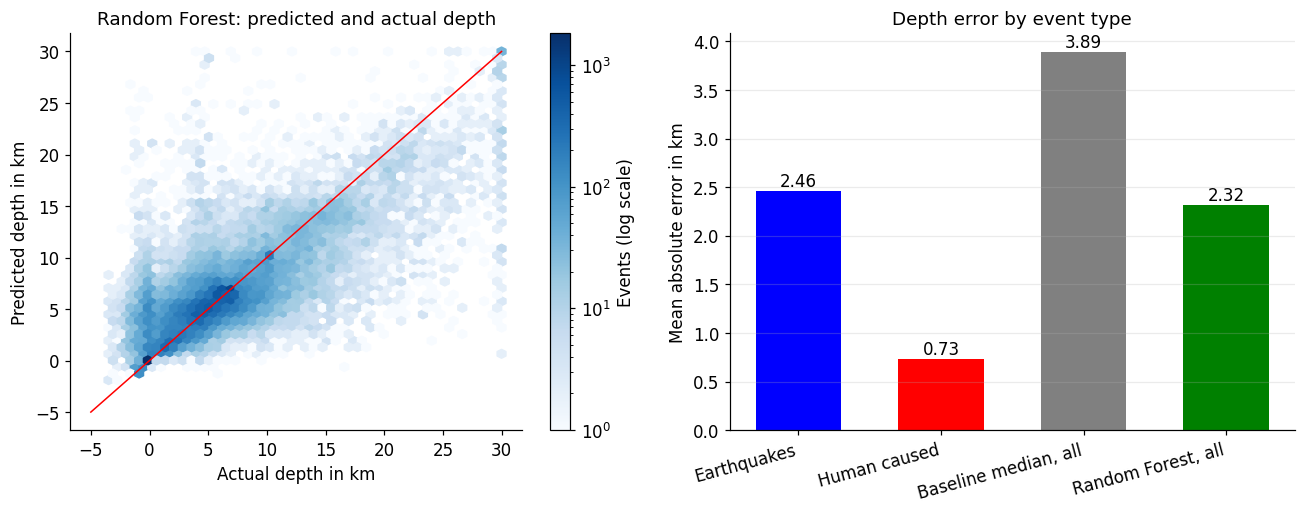

{'Earthquakes': np.float64(2.462), 'Human caused': np.float64(0.733), 'Baseline median, all': np.float64(3.887), 'Random Forest, all': np.float64(2.319)}
            mean   size
mag                    
[2.0, 2.5)  2.41  21745
[2.5, 3.0)  2.23   7327
[3.0, 3.5)  1.93   2978
[3.5, 4.0)  2.07    732
[4.0, 8.0)  2.21    399


In [7]:

cand = [m for m in summarize(depth_A).index if not m.startswith('Baseline')]
best_name = cand[0]
pred = preds_A[best_name]
print('Best depth model (six predictors):', best_name)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
hb = ax[0].hexbin(df['depth'].clip(-5, 30), pred.clip(-5, 30), gridsize=45, cmap='Blues', bins='log', mincnt=1)
plt.colorbar(hb, ax=ax[0], label='Events (log scale)')
ax[0].plot([-5, 30], [-5, 30], color=MAN, lw=1)
ax[0].set_xlabel('Actual depth in km'); ax[0].set_ylabel('Predicted depth in km')
ax[0].set_title(f'{best_name}: predicted and actual depth'); ax[0].grid(False)
err = (pred - df['depth']).abs()
groups = {'Earthquakes': err[df['is_manmade'] == 0].mean(), 'Human caused': err[df['is_manmade'] == 1].mean(),
          'Baseline median, all': (df['depth'] - df['depth'].median()).abs().mean(), f'{best_name}, all': err.mean()}
ax[1].bar(groups.keys(), groups.values(), color=[NAT, MAN, GRY, NEU], width=0.6)
for i, v in enumerate(groups.values()):
    ax[1].text(i, v + 0.05, f'{v:.2f}', ha='center')
ax[1].set_ylabel('Mean absolute error in km'); ax[1].set_title('Depth error by event type'); ax[1].grid(axis='x', alpha=0)
plt.setp(ax[1].get_xticklabels(), rotation=15, ha='right')
plt.tight_layout(); save('fig02_depth_best_model')
print({k: round(v, 3) for k, v in groups.items()})
mag_bins = pd.cut(df['mag'], [2, 2.5, 3, 3.5, 4, 8], right=False)
print(err.groupby(mag_bins, observed=True).agg(['mean', 'size']).round(2))

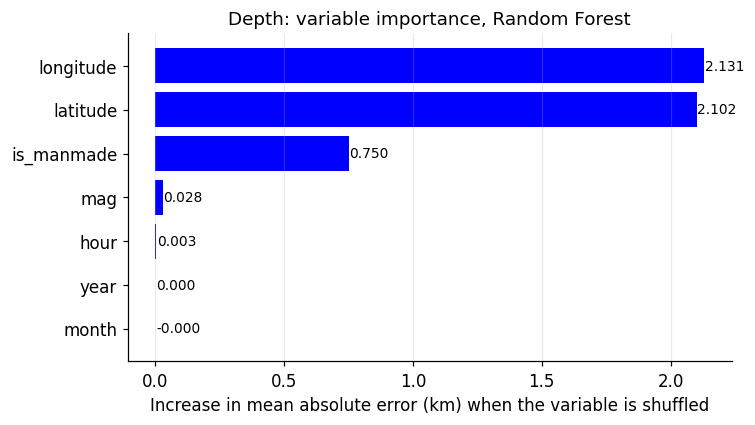

month        -0.0002
year          0.0000
hour          0.0031
mag           0.0277
is_manmade    0.7497
latitude      2.1016
longitude     2.1309
dtype: float64


In [8]:

def perm_importance(tag, model_name, features, target, scoring):
    imp = []
    for yr in YEARS:
        te = df[df['year'] == yr]
        r = permutation_importance(fitted[(tag, model_name, yr)], te[features], te[target],
                                   n_repeats=5, random_state=SEED, scoring=scoring)
        imp.append(r.importances_mean)
    return pd.Series(np.mean(imp, axis=0), index=features)

imp_depth = perm_importance('B', best_name, FEAT_DEPTH_PLUS, 'depth', 'neg_mean_absolute_error').sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_depth.index, imp_depth.values, color=NAT)
for i, v in enumerate(imp_depth.values):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('Increase in mean absolute error (km) when the variable is shuffled')
ax.set_title(f'Depth: variable importance, {best_name}'); ax.grid(axis='y', alpha=0)
plt.tight_layout(); save('fig03_depth_importance')
print(imp_depth.round(4))

In [11]:

clf_models = {
    'Always earthquake': (DummyClassifier(strategy='most_frequent'), {}),
    'Naive Bayes': (GaussianNB(), {}),
    'Random Forest': (RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
                      {'min_samples_leaf': [1, 5]}),
}

def run_type(features, tag):
    res, probs = [], {}
    for yr in YEARS:
        tr, te = df[df['year'] != yr], df[df['year'] == yr]
        Xtr, ytr, Xte, yte = tr[features], tr['is_manmade'], te[features], te['is_manmade']
        for name, (model, grid) in clf_models.items():
            best, par = tune(model, grid, Xtr, ytr, tr['year'], 'average_precision')
            fitted[(tag, name, yr)] = best
            p = best.predict_proba(Xte)[:, 1] if hasattr(best, 'predict_proba') and name != 'Always earthquake' else np.zeros(len(te))
            yhat = (p >= 0.5).astype(int)
            if name == 'Always earthquake':
                yhat = np.zeros(len(te), dtype=int)
            res.append([name, yr, recall_score(yte, yhat, zero_division=0), precision_score(yte, yhat, zero_division=0),
                        f1_score(yte, yhat, zero_division=0),
                        average_precision_score(yte, p) if name != 'Always earthquake' else yte.mean(),
                        roc_auc_score(yte, p) if name != 'Always earthquake' else 0.5,
                        (yhat == yte).mean()])
            probs.setdefault(name, []).append(pd.Series(p, index=te.index))
    out = pd.DataFrame(res, columns=['model', 'held_out_year', 'recall', 'precision', 'F1', 'PR_AUC', 'ROC_AUC', 'accuracy'])
    probs = {k: pd.concat(v).sort_index() for k, v in probs.items()}
    return out, probs

type_A, probs_A = run_type(FEAT_TYPE, 'TA')
type_B, probs_B = run_type(FEAT_TYPE + ['depth'], 'TB')
def summ_type(res):
    return res.groupby('model')[['recall', 'precision', 'F1', 'PR_AUC', 'ROC_AUC', 'accuracy']].agg(['mean', 'std']).round(3)
print('Event type, no depth. Mean and standard deviation over the six held out years')
print(summ_type(type_A))
print('\nEvent type, with depth added (a leakage check, not our real model)')
print(summ_type(type_B))
print('\nRandom Forest, no depth, each held out year')
print(type_A[type_A['model'] == 'Random Forest'].round(3).to_string(index=False))

Event type, no depth. Mean and standard deviation over the six held out years
                  recall        precision            F1        PR_AUC         \
                    mean    std      mean    std   mean    std   mean    std   
model                                                                          
Always earthquake  0.000  0.000     0.000  0.000  0.000  0.000  0.081  0.043   
Naive Bayes        0.615  0.155     0.618  0.154  0.615  0.152  0.648  0.134   
Random Forest      0.890  0.031     0.974  0.015  0.930  0.021  0.971  0.020   

                  ROC_AUC        accuracy         
                     mean    std     mean    std  
model                                             
Always earthquake   0.500  0.000    0.919  0.043  
Naive Bayes         0.842  0.067    0.948  0.013  
Random Forest       0.993  0.004    0.990  0.003  

Event type, with depth added (a leakage check, not our real model)
                  recall        precision            F1        PR_A

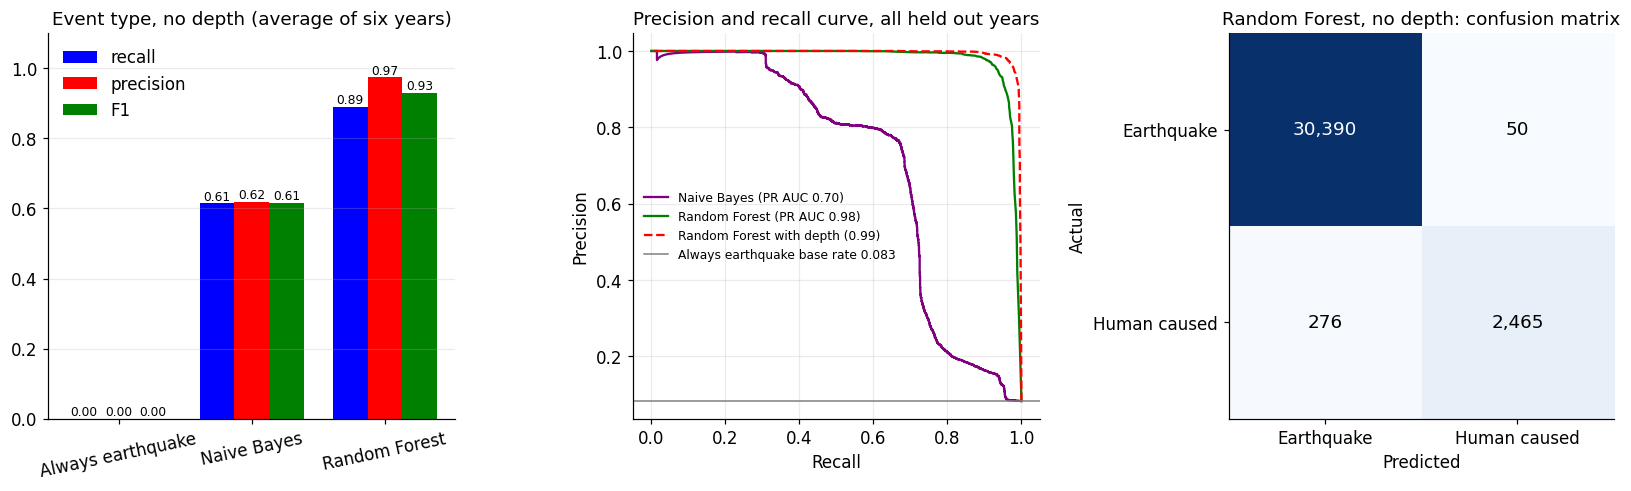

Confusion matrix (rows actual, columns predicted):
[[30390    50]
 [  276  2465]]


In [12]:

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
mods = ['Always earthquake', 'Naive Bayes', 'Random Forest']
met = ['recall', 'precision', 'F1']
w = 0.26
for j, (m, c) in enumerate(zip(met, [NAT, MAN, NEU])):
    vals = [type_A[type_A['model'] == k][m].mean() for k in mods]
    ax[0].bar(np.arange(3) + (j - 1) * w, vals, w, color=c, label=m)
    for i, v in enumerate(vals):
        ax[0].text(i + (j - 1) * w, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(mods, rotation=12)
ax[0].set_ylim(0, 1.1); ax[0].set_title('Event type, no depth (average of six years)'); ax[0].legend(); ax[0].grid(axis='x', alpha=0)
yall = df['is_manmade']
for name, c in [('Naive Bayes', PUR), ('Random Forest', NEU)]:
    p, r, _ = precision_recall_curve(yall, probs_A[name])
    ax[1].plot(r, p, color=c, label=f'{name} (PR AUC {average_precision_score(yall, probs_A[name]):.2f})')
p, r, _ = precision_recall_curve(yall, probs_B['Random Forest'])
ax[1].plot(r, p, color=MAN, ls='--', label=f'Random Forest with depth ({average_precision_score(yall, probs_B["Random Forest"]):.2f})')
ax[1].axhline(yall.mean(), color=GRY, lw=1, label=f'Always earthquake base rate {yall.mean():.3f}')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision and recall curve, all held out years')
ax[1].legend(fontsize=8)
cm = confusion_matrix(yall, (probs_A['Random Forest'] >= 0.5).astype(int))
im = ax[2].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(['Earthquake', 'Human caused']); ax[2].set_yticks([0, 1]); ax[2].set_yticklabels(['Earthquake', 'Human caused'])
ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('Actual'); ax[2].set_title('Random Forest, no depth: confusion matrix'); ax[2].grid(False)
plt.tight_layout(); save('fig04_type_results')
print('Confusion matrix (rows actual, columns predicted):'); print(cm)

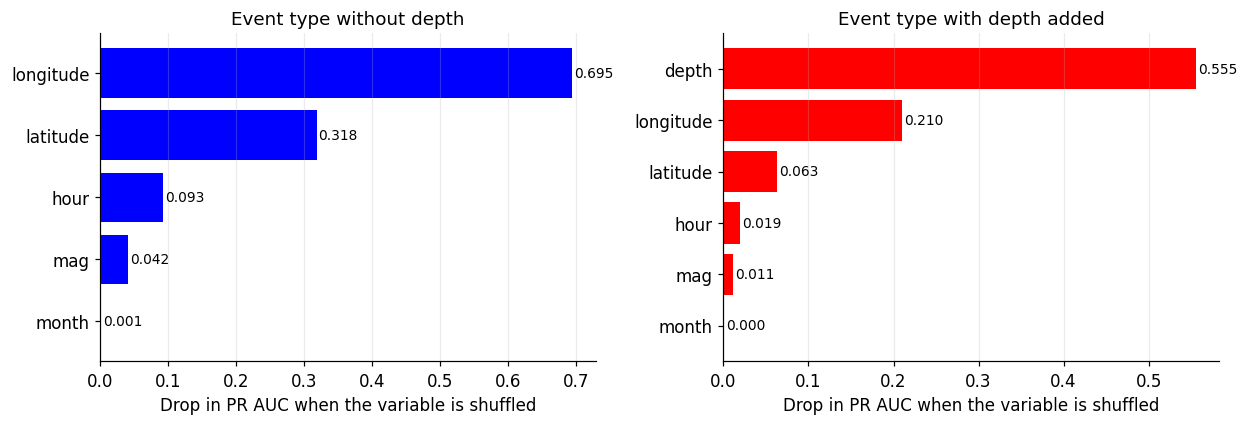

month        0.0009
mag          0.0416
hour         0.0930
latitude     0.3184
longitude    0.6950
dtype: float64
month        0.0001
mag          0.0108
hour         0.0193
latitude     0.0627
longitude    0.2098
depth        0.5552
dtype: float64


In [13]:

imp_type = perm_importance('TA', 'Random Forest', FEAT_TYPE, 'is_manmade', 'average_precision').sort_values()
imp_type_d = perm_importance('TB', 'Random Forest', FEAT_TYPE + ['depth'], 'is_manmade', 'average_precision').sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].barh(imp_type.index, imp_type.values, color=NAT)
for i, v in enumerate(imp_type.values):
    ax[0].text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax[0].set_title('Event type without depth'); ax[0].set_xlabel('Drop in PR AUC when the variable is shuffled'); ax[0].grid(axis='y', alpha=0)
ax[1].barh(imp_type_d.index, imp_type_d.values, color=MAN)
for i, v in enumerate(imp_type_d.values):
    ax[1].text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax[1].set_title('Event type with depth added'); ax[1].set_xlabel('Drop in PR AUC when the variable is shuffled'); ax[1].grid(axis='y', alpha=0)
plt.tight_layout(); save('fig05_type_importance')
print(imp_type.round(4)); print(imp_type_d.round(4))

Silhouette score for each k: {3: np.float64(0.509), 4: np.float64(0.494), 5: np.float64(0.514), 6: np.float64(0.512), 7: np.float64(0.471), 8: np.float64(0.537), 9: np.float64(0.537), 10: np.float64(0.542)}
         events  human_caused_percent  median_depth  mean_mag  center_lat  \
cluster                                                                     
4          5769                  2.06          4.47      2.49       39.87   
0          7637                  3.42          5.54      2.40       36.13   
5          3871                  0.62          5.60      2.41       38.24   
2          7216                  4.79          4.24      2.37       34.97   
6          4896                  1.23          6.71      2.48       32.53   
3          2217                 20.88          3.56      2.45       40.74   
7           689                 87.66          0.00      2.76       33.71   
1           886                 97.52          0.00      3.09       43.69   

         center_lon  


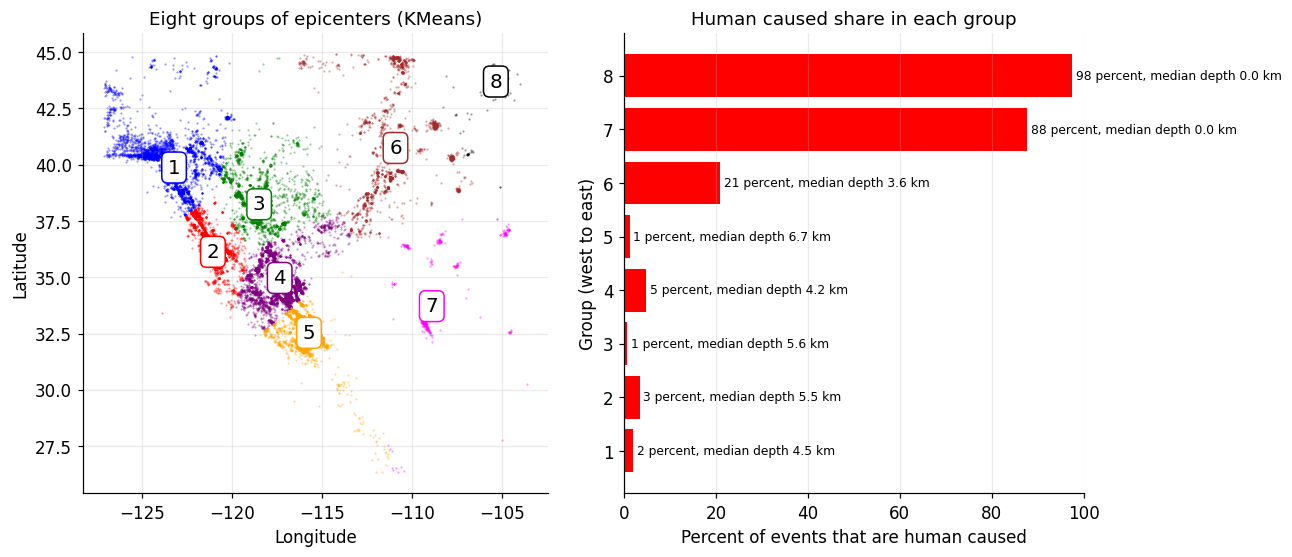

In [14]:

xy = df[['latitude', 'longitude']].values
sil = {}
samp = np.random.RandomState(SEED).choice(len(xy), 6000, replace=False)
for k in range(3, 11):
    lab = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit_predict(xy)
    sil[k] = silhouette_score(xy[samp], lab[samp])
print('Silhouette score for each k:', {k: round(v, 3) for k, v in sil.items()})
K = 8
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(xy)
df['cluster'] = km.labels_
summ = df.groupby('cluster').agg(events=('depth', 'size'), human_caused_percent=('is_manmade', lambda s: s.mean() * 100),
                                  median_depth=('depth', 'median'), mean_mag=('mag', 'mean'),
                                  center_lat=('latitude', 'mean'), center_lon=('longitude', 'mean')).round(2)
print(summ.sort_values('center_lon'))
order = summ.sort_values('center_lon').index.tolist()
cols8 = ['blue', 'red', 'green', 'purple', 'orange', 'brown', 'magenta', 'black']
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1.2, 1]})
for k, c in zip(order, cols8):
    g = df[df['cluster'] == k]
    ax[0].scatter(g['longitude'], g['latitude'], s=2, alpha=0.4, color=c, linewidths=0)
    ax[0].text(g['longitude'].mean(), g['latitude'].mean(), str(order.index(k) + 1), fontsize=13, ha='center', va='center',
               bbox=dict(boxstyle='round', fc='white', ec=c))
ax[0].set_xlabel('Longitude'); ax[0].set_ylabel('Latitude'); ax[0].set_title('Eight groups of epicenters (KMeans)'); ax[0].set_aspect(1.25)
ax[1].barh([str(order.index(k) + 1) for k in order], [summ.loc[k, 'human_caused_percent'] for k in order], color=MAN)
for i, k in enumerate(order):
    ax[1].text(summ.loc[k, 'human_caused_percent'] + 0.8, i, f"{summ.loc[k, 'human_caused_percent']:.0f} percent, median depth {summ.loc[k, 'median_depth']:.1f} km", va='center', fontsize=8)
ax[1].set_xlim(0, 100); ax[1].set_xlabel('Percent of events that are human caused'); ax[1].set_ylabel('Group (west to east)')
ax[1].set_title('Human caused share in each group'); ax[1].grid(axis='y', alpha=0)
plt.tight_layout(); save('fig06_clusters')

In [15]:
# save all result tables and zip the figures
depth_A.to_csv('results_depth_six_predictors.csv', index=False)
depth_B.to_csv('results_depth_plus_is_manmade.csv', index=False)
type_A.to_csv('results_type_no_depth.csv', index=False)
type_B.to_csv('results_type_with_depth.csv', index=False)
import shutil
shutil.make_archive('figures_method', 'zip', FIG)
try:
    from google.colab import files
    files.download('figures_method.zip')
except Exception:
    print('Saved figures_method.zip in the current folder')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>